In [7]:
from sklearn.ensemble import GradientBoostingClassifier

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier

df = pd.read_csv("../data/processed/bank_churn_features.csv")
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                   max_depth=3, random_state=42)
model.fit(X_train, y_train)
cutoff = 0.30

probs = model.predict_proba(X_test)[:, 1]
pred = (probs >= cutoff).astype(int)
print(confusion_matrix(y_test, pred))

[[1432  161]
 [ 141  266]]


In [9]:
importance = pd.Series(model.feature_importances_, index=X_train.columns)
importance.sort_values(ascending=False).round(3)

Age                       0.360
NumOfProducts             0.258
EngagementProduct         0.074
Balance                   0.072
Geography_Germany         0.057
IsActiveMember            0.046
EstimatedSalary           0.034
BalanceSalaryRatio_log    0.033
CreditScore               0.025
TenureByAge               0.014
Gender_Male               0.012
ProductDensity            0.007
HasCrCard                 0.002
Geography_Spain           0.002
Tenure                    0.001
dtype: float64

In [10]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print(shap_values.values.shape)

row = 0
print("Churn probability:", round(probs[row], 3), "| Actually churned:", y_test.iloc[row])
contrib = pd.Series(shap_values.values[row], index=X_test.columns)
print(X_test.iloc[row][["Age", "NumOfProducts", "IsActiveMember", "Geography_Germany"]])
contrib.sort_values(key=abs, ascending=False).head(6).round(2)

(2000, 15)
Churn probability: 0.022 | Actually churned: 0
Age                  36.0
NumOfProducts         2.0
IsActiveMember        0.0
Geography_Germany     0.0
Name: 5702, dtype: float64


NumOfProducts            -1.05
Age                      -0.51
Gender_Male              -0.21
BalanceSalaryRatio_log   -0.19
EngagementProduct         0.16
IsActiveMember            0.12
dtype: float64

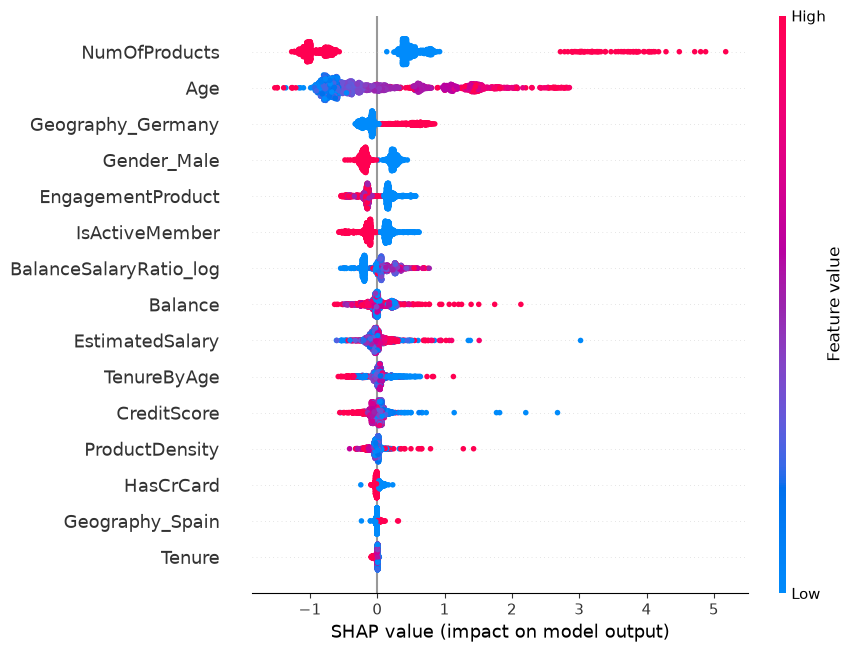

In [11]:
shap.plots.beeswarm(shap_values, max_display=15)

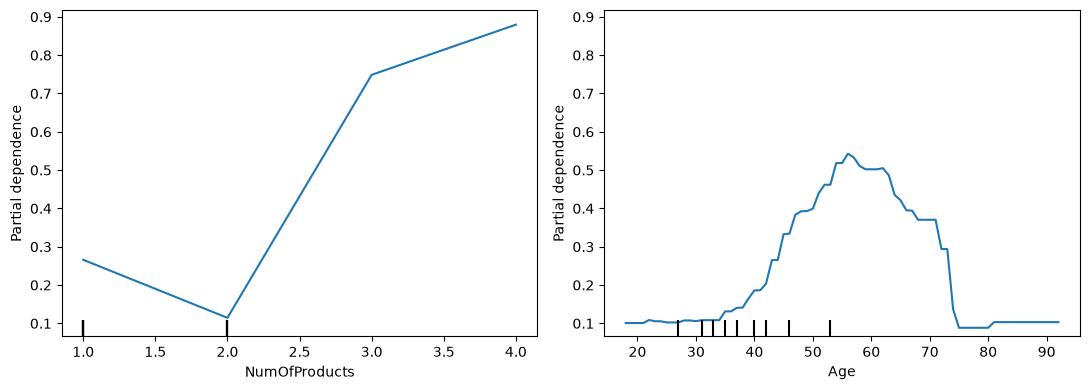

In [14]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

X_train_float = X_train.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
PartialDependenceDisplay.from_estimator(
    model, X_train_float, ["NumOfProducts", "Age"],
    response_method="predict_proba", method="brute", ax=ax
)
plt.tight_layout()
plt.show()